# Benchmark, baseline y pruebas estadísticas

Las predicciones de 2025 se cargan de `resultados/predicciones_prueba.npz` (generadas por `src/corridas.py`). Aquí
no se entrena nada: solo se evalúa el conjunto de prueba, que estuvo congelado hasta este punto.

In [1]:
import os
os.environ["MKL_NUM_THREADS"] = "1"   # con varios hilos, np.linalg.solve se bloquea en este equipo (MKL 2025)
import json, sys, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import bds
sys.path.insert(0, "src")
from datos import cargar

warnings.simplefilter("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
d = cargar()
L, H = d["L"], d["H"]
ix = d["idx"]["prueba"]
y = d["y"][ix + L - 1 + H]                      # velocidad observada en t + 24
pers = d["y"][ix + L - 1]                       # persistencia: v_t
est = d["estacion"]["prueba"]
hora = d["tiempo"][ix + L - 1 + H]
P = np.load("resultados/predicciones_prueba.npz")
corr = pd.DataFrame(json.load(open("resultados/corridas.json")))
MOD = ["MLP", "LSTM", "CNN"]
semillas = sorted({int(k.split("_")[1]) for k in P.files})
print(f"{len(y):,} ventanas de prueba | {len(set(est))} estaciones | {len(semillas)} semillas por modelo")

211,408 ventanas de prueba | 62 estaciones | 6 semillas por modelo


## Tabla comparativa

Cada modelo se entrenó con $R = 6$ semillas. Se reporta la media, la desviación estándar y el **intervalo de
confianza al 95 %** entre semillas (t de Student con 5 grados de libertad), el MASE (MAE del modelo sobre el MAE
de la persistencia a 24 h), el tiempo de entrenamiento y el de inferencia sobre todo 2025. Con $h = 24$ la
persistencia coincide con el **ingenuo estacional** diario ($\hat v_{t+24} = v_{t+24-24}$), así que una sola
referencia cubre las dos que pide el enunciado. Hardware: GPU NVIDIA RTX 4060 Ti (8 GB), CPU AMD Ryzen 7 8700F,
32 GB de RAM.

In [2]:
def metricas(p):
    e = p - y
    return dict(RMSE=np.sqrt(np.mean(e ** 2)), MAE=np.mean(np.abs(e)), R2=1 - np.mean(e ** 2) / np.var(y))

mae_p = np.mean(np.abs(pers - y))
t975 = stats.t.ppf(0.975, len(semillas) - 1)
filas, por_semilla = [], []
for m in MOD:
    met = pd.DataFrame([metricas(P[f"{m}_{s}"]) for s in semillas])
    met["MASE"] = met.MAE / mae_p
    por_semilla += [dict(modelo=m, semilla=s, **r) for s, r in zip(semillas, met.to_dict("records"))]
    c = corr[corr.modelo == m]
    mitad = t975 * met.RMSE.std(ddof=1) / np.sqrt(len(met))
    filas.append({"Modelo": m, "RMSE media": met.RMSE.mean(), "RMSE de": met.RMSE.std(ddof=1),
                  "RMSE IC95 inf": met.RMSE.mean() - mitad, "RMSE IC95 sup": met.RMSE.mean() + mitad,
                  "MAE media": met.MAE.mean(), "MAE de": met.MAE.std(ddof=1), "R2 media": met.R2.mean(),
                  "MASE media": met.MASE.mean(), "Parámetros": int(c.parametros.iloc[0]), "Épocas": c.epocas.mean(),
                  "Segundos entrenamiento": c.segundos.mean(),
                  "Segundos inferencia 2025": c.segundos_inferencia_prueba.mean()})
mp = metricas(pers)
filas.append({"Modelo": "Persistencia", "RMSE media": mp["RMSE"], "RMSE de": 0.0, "RMSE IC95 inf": mp["RMSE"],
              "RMSE IC95 sup": mp["RMSE"], "MAE media": mp["MAE"], "MAE de": 0.0, "R2 media": mp["R2"],
              "MASE media": 1.0, "Parámetros": 0, "Épocas": 0, "Segundos entrenamiento": 0, "Segundos inferencia 2025": 0})
tabla = pd.DataFrame(filas).set_index("Modelo")
ps = pd.DataFrame(por_semilla)
tabla.round(4)

,RMSE media,RMSE de,RMSE IC95 inf,RMSE IC95 sup,MAE media,MAE de,R2 media,MASE media,Parámetros,Épocas,Segundos entrenamiento,Segundos inferencia 2025
Modelo,,,,,,,,,,,,
MLP,0.7057,0.0024,0.7031,0.7082,0.4979,0.0029,0.7528,0.8539,102785,13.0000,7.1149,0.0241
LSTM,0.7086,0.0019,0.7066,0.7106,0.4997,0.0055,0.7507,0.8569,13345,12.3333,58.3212,0.3951
CNN,0.7141,0.0053,0.7085,0.7196,0.5058,0.0047,0.7468,0.8674,44129,14.8333,31.1345,0.4362
Persistencia,0.8503,0.0000,0.8503,0.8503,0.5831,0.0000,0.6410,1.0000,0,0.0000,0.0000,0.0000


### Diferencias relativas de error

Reducción relativa del error de cada modelo respecto al peor modelo base, al mejor y a la persistencia:
$\Delta\text{RMSE} = (\text{RMSE}_{\text{ref}} - \text{RMSE}_{\text{modelo}}) / \text{RMSE}_{\text{ref}} \times 100\,\%$,
y lo mismo para el MAE.

In [3]:
base = tabla.loc[MOD]
peor, mejor_m = base["RMSE media"].idxmax(), base["RMSE media"].idxmin()
delta = pd.DataFrame({
    f"ΔRMSE vs peor ({peor}) %": 100 * (base.loc[peor, "RMSE media"] - base["RMSE media"]) / base.loc[peor, "RMSE media"],
    f"ΔRMSE vs mejor ({mejor_m}) %": 100 * (base.loc[mejor_m, "RMSE media"] - base["RMSE media"]) / base.loc[mejor_m, "RMSE media"],
    "ΔRMSE vs persistencia %": 100 * (mp["RMSE"] - base["RMSE media"]) / mp["RMSE"],
    f"ΔMAE vs peor ({peor}) %": 100 * (base.loc[peor, "MAE media"] - base["MAE media"]) / base.loc[peor, "MAE media"],
    "ΔMAE vs persistencia %": 100 * (mp["MAE"] - base["MAE media"]) / mp["MAE"]})
delta.round(2)

,ΔRMSE vs peor (CNN) %,ΔRMSE vs mejor (MLP) %,ΔRMSE vs persistencia %,ΔMAE vs peor (CNN) %,ΔMAE vs persistencia %
Modelo,,,,,
MLP,1.18,0.00,17.01,1.56,14.61
LSTM,0.76,-0.42,16.66,1.22,14.31
CNN,0.00,-1.19,16.02,0.00,13.26


### Descomposición de la varianza: semillas frente a modelos

¿Cuánto de la variación del RMSE de prueba entre las 18 corridas se debe a la arquitectura y cuánto al azar del
entrenamiento (la semilla)? Se usa un ANOVA de un factor sobre el RMSE por corrida.

In [4]:
media_total = ps.RMSE.mean()
ss_mod = sum(len(g) * (g.RMSE.mean() - media_total) ** 2 for _, g in ps.groupby("modelo"))
ss_sem = sum(((g.RMSE - g.RMSE.mean()) ** 2).sum() for _, g in ps.groupby("modelo"))
print(f"Varianza explicada por el modelo: {ss_mod / (ss_mod + ss_sem):.1%} | por la semilla: {ss_sem / (ss_mod + ss_sem):.1%}")
an = stats.f_oneway(*[g.RMSE for _, g in ps.groupby("modelo")])
print(f"ANOVA de un factor: F = {an.statistic:.2f}, p = {an.pvalue:.2e}")

Varianza explicada por el modelo: 53.9% | por la semilla: 46.1%
ANOVA de un factor: F = 8.79, p = 2.98e-03


### Referencia de contexto: regresión lineal regularizada

Una regresión ridge sobre la misma ventana aplanada (672 entradas) es el equivalente con pérdida cuadrática de la
SVR lineal. No es un modelo base (no es Deep Learning); sirve para medir cuánto aporta la no linealidad. El
parámetro de regularización se elige en validación.

In [5]:
def gram(ix_, lote=20000):
    A = np.zeros((L * 4 + 1, L * 4 + 1)); b_ = np.zeros(L * 4 + 1)
    for i0 in range(0, len(ix_), lote):
        j = ix_[i0:i0 + lote]
        Xb = np.hstack([d["X"][j[:, None] + np.arange(L)].reshape(len(j), -1), np.ones((len(j), 1))]).astype(np.float64)
        A += Xb.T @ Xb; b_ += Xb.T @ d["y"][j + L - 1 + H]
    return A, b_

def pred_lineal(w, ix_, lote=20000):
    return np.concatenate([np.hstack([d["X"][j[:, None] + np.arange(L)].reshape(len(j), -1), np.ones((len(j), 1))]) @ w
                           for j in np.array_split(ix_, max(1, len(ix_) // lote))])

A, b_ = gram(d["idx"]["entrenamiento"])
iv = d["idx"]["validacion"]; yv = d["y"][iv + L - 1 + H]
mejor_rid = None
for alfa in [1e0, 1e1, 1e2, 1e3, 1e4, 1e5]:
    w = np.linalg.solve(A + alfa * np.diag(np.r_[np.ones(L * 4), 0]), b_)
    r = np.sqrt(np.mean((pred_lineal(w, iv) - yv) ** 2))
    if mejor_rid is None or r < mejor_rid[1]:
        mejor_rid = (alfa, r, w)
alfa, r_val, w = mejor_rid
p_rid = pred_lineal(w, ix)
print(f"Ridge (α = {alfa:g}): RMSE validación {r_val:.4f} | RMSE prueba 2025 {np.sqrt(np.mean((p_rid - y) ** 2)):.4f} m/s")

Ridge (α = 10000): RMSE validación 0.7890 | RMSE prueba 2025 0.6982 m/s


## Pronóstico promedio por modelo

Para las pruebas por estación y por hora se usa el **promedio de las $R$ semillas** de cada modelo, que es el
pronóstico que se pondría en producción; la variabilidad entre semillas ya quedó en la tabla anterior.

In [6]:
pm = {m: np.mean([P[f"{m}_{s}"] for s in semillas], axis=0) for m in MOD}
pm["Persistencia"] = pers
err2 = pd.DataFrame({m: (p - y) ** 2 for m, p in pm.items()})
err2["estacion"], err2["hora"] = est, hora
rmse_est = err2.groupby("estacion")[list(pm)].mean() ** 0.5
print(f"RMSE por estación ({len(rmse_est)} estaciones), mediana:")
print(rmse_est.median().round(4).to_string())
print("\nRMSE del promedio de semillas:", {m: round(float(np.sqrt(err2[m].mean())), 4) for m in pm})

RMSE por estación (62 estaciones), mediana:
MLP             0.5578
LSTM            0.5601
CNN             0.5755
Persistencia    0.7238

RMSE del promedio de semillas: {'MLP': 0.701, 'LSTM': 0.7022, 'CNN': 0.7065, 'Persistencia': 0.8503}


## Ranking y prueba de Friedman (estaciones como bloques)

La estación es la unidad de independencia declarada a priori, así que cada estación es un bloque y se comparan los
rangos del RMSE de los cuatro pronósticos.

In [7]:
fr = stats.friedmanchisquare(*[rmse_est[m] for m in pm])
rangos = rmse_est.rank(axis=1).mean().sort_values()
print(f"Friedman: chi2 = {fr.statistic:.2f}, p = {fr.pvalue:.2e}")
print("Rango medio (1 = mejor):"); print(rangos.round(2).to_string())

Friedman: chi2 = 107.85, p = 3.19e-23
Rango medio (1 = mejor):
MLP             1.82
LSTM            1.98
CNN             2.24
Persistencia    3.95


Post-hoc de Nemenyi: dos pronósticos difieren si sus rangos medios se separan más que la diferencia crítica
$CD = q_{0.05}\sqrt{k(k+1)/(6N)}$, con $k = 4$ pronósticos y $N$ estaciones ($q_{0.05} = 2.569$).

In [8]:
k_, N_ = len(pm), len(rmse_est)
CD = 2.569 * np.sqrt(k_ * (k_ + 1) / (6 * N_))
print(f"Diferencia crítica de Nemenyi: {CD:.3f}")
for i, a in enumerate(rangos.index):
    for b in rangos.index[i + 1:]:
        print(f"  {a} vs {b}: diferencia de rangos {abs(rangos[a] - rangos[b]):.2f} → "
              f"{'difieren' if abs(rangos[a] - rangos[b]) > CD else 'no difieren'}")

Diferencia crítica de Nemenyi: 0.596
  MLP vs LSTM: diferencia de rangos 0.16 → no difieren
  MLP vs CNN: diferencia de rangos 0.42 → no difieren
  MLP vs Persistencia: diferencia de rangos 2.13 → difieren
  LSTM vs CNN: diferencia de rangos 0.26 → no difieren
  LSTM vs Persistencia: diferencia de rangos 1.97 → difieren
  CNN vs Persistencia: diferencia de rangos 1.71 → difieren


### Comparaciones por pares: Wilcoxon con corrección de Holm, diferencia de RMSE y tamaño del efecto

Para cada par se usan las diferencias de RMSE por estación. El tamaño del efecto es la $d$ de Cohen para datos
pareados (media de las diferencias sobre su desviación estándar) y el intervalo de confianza al 95 % de la
diferencia media sale de un bootstrap por estaciones.

In [9]:
pares = [(a, b) for i, a in enumerate(pm) for b in list(pm)[i + 1:]]
rng = np.random.default_rng(0)
filas = []
for a, b in pares:
    dif = (rmse_est[a] - rmse_est[b]).to_numpy()
    boot = [rng.choice(dif, len(dif)).mean() for _ in range(5000)]
    filas.append({"Par": f"{a} − {b}", "ΔRMSE medio": dif.mean(), "IC 95 % inf": np.percentile(boot, 2.5),
                  "IC 95 % sup": np.percentile(boot, 97.5), "d de Cohen": dif.mean() / dif.std(ddof=1),
                  "p Wilcoxon": stats.wilcoxon(dif).pvalue})
wil = pd.DataFrame(filas).set_index("Par")
wil["p Holm"] = multipletests(wil["p Wilcoxon"], method="holm")[1]
wil["Significativo"] = wil["p Holm"] < 0.05
wil.round(4)

,ΔRMSE medio,IC 95 % inf,IC 95 % sup,d de Cohen,p Wilcoxon,p Holm,Significativo
Par,,,,,,,
MLP − LSTM,0.0004,-0.0037,0.0048,0.0245,0.6663,0.6663,False
MLP − CNN,-0.0031,-0.0077,0.0013,-0.1681,0.0476,0.0953,False
MLP − Persistencia,-0.1449,-0.1602,-0.1301,-2.3693,0.0000,0.0000,True
LSTM − CNN,-0.0036,-0.0071,-0.0005,-0.2645,0.0154,0.0463,True
LSTM − Persistencia,-0.1453,-0.1592,-0.1312,-2.5619,0.0000,0.0000,True
CNN − Persistencia,-0.1418,-0.1564,-0.1281,-2.4753,0.0000,0.0000,True


Supuesto de normalidad de las diferencias (relevante para la $d$ de Cohen y la prueba t de la equivalencia):

MLP − LSTM: Shapiro-Wilk p = 0.000
MLP − CNN: Shapiro-Wilk p = 0.000
MLP − Persistencia: Shapiro-Wilk p = 0.049
LSTM − CNN: Shapiro-Wilk p = 0.000
LSTM − Persistencia: Shapiro-Wilk p = 0.102
CNN − Persistencia: Shapiro-Wilk p = 0.212


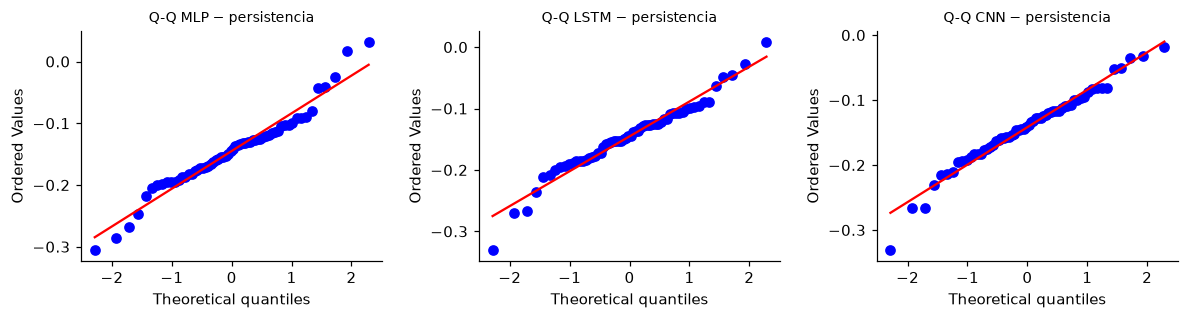

In [10]:
for a, b in pares:
    dif = rmse_est[a] - rmse_est[b]
    print(f"{a} − {b}: Shapiro-Wilk p = {stats.shapiro(dif).pvalue:.3f}")
fig, ax = plt.subplots(1, 3, figsize=(11, 3))
for a_, (a, b) in zip(ax, [(m, "Persistencia") for m in MOD]):
    stats.probplot(rmse_est[a] - rmse_est[b], plot=a_); a_.set_title(f"Q-Q {a} − persistencia", fontsize=9)
plt.tight_layout(); plt.show()

## Diebold–Mariano con corrección de Harvey–Leybourne–Newbold

La prueba de Diebold–Mariano {cite}`diebold1995` compara la pérdida cuadrática de dos pronósticos hora a hora.
Se promedia el diferencial de pérdida entre las estaciones activas en cada hora, para obtener una sola serie
temporal, y se usa la varianza de largo plazo con $h - 1 = 23$ rezagos (el pronóstico es a 24 h, así que los errores
consecutivos se solapan) y la corrección para muestras finitas de {cite}`harvey1997`.

In [11]:
def dm_hln(dl, h=24):
    dl = np.asarray(dl); T = len(dl); dbar = dl.mean(); u = dl - dbar
    gam = [u @ u / T] + [u[k:] @ u[:-k] / T for k in range(1, h)]
    v = (gam[0] + 2 * sum(gam[1:])) / T
    dm = dbar / np.sqrt(v)
    hln = dm * np.sqrt((T + 1 - 2 * h + h * (h - 1) / T) / T)
    return hln, 2 * stats.t.sf(abs(hln), df=T - 1)

filas = []
for a, b in pares:
    serie = (err2[a] - err2[b]).groupby(err2.hora).mean().sort_index()
    est_, p = dm_hln(serie)
    filas.append({"Par": f"{a} − {b}", "Diferencial medio": serie.mean(), "DM-HLN": est_, "p": p})
dm = pd.DataFrame(filas).set_index("Par")
dm["p Holm"] = multipletests(dm.p, method="holm")[1]
dm.round(4)

,Diferencial medio,DM-HLN,p,p Holm
Par,,,,
MLP − LSTM,0.0019,0.4418,0.6586,0.6586
MLP − CNN,-0.0049,-1.2994,0.1939,0.3877
MLP − Persistencia,-0.2357,-19.8874,0.0000,0.0000
LSTM − CNN,-0.0068,-3.3698,0.0008,0.0023
LSTM − Persistencia,-0.2376,-22.4369,0.0000,0.0000
CNN − Persistencia,-0.2308,-20.6239,0.0000,0.0000


Un diferencial negativo indica que el primer modelo del par tiene menor error cuadrático.

## Equivalencia práctica (TOST) entre los dos mejores modelos

Que una diferencia no sea significativa no prueba que los modelos sean iguales. La prueba TOST contrasta si la
diferencia media de RMSE por estación cae dentro del margen declarado a priori, $\pm\delta = \pm 0.02$ m/s.

In [12]:
delta = 0.02
mejores = [m for m in rangos.index if m != "Persistencia"][:2]
dif = (rmse_est[mejores[0]] - rmse_est[mejores[1]]).to_numpy()
p_inf = stats.ttest_1samp(dif, -delta, alternative="greater").pvalue
p_sup = stats.ttest_1samp(dif, delta, alternative="less").pvalue
print(f"{mejores[0]} − {mejores[1]}: diferencia media {dif.mean():.4f} m/s | TOST p = {max(p_inf, p_sup):.4f}")
print("Equivalentes dentro de ±δ" if max(p_inf, p_sup) < 0.05 else "No se puede afirmar equivalencia dentro de ±δ")

MLP − LSTM: diferencia media 0.0004 m/s | TOST p = 0.0000
Equivalentes dentro de ±δ


## Diagnóstico de los residuos del mejor modelo

Si el pronóstico aprovechara toda la información, los residuos no tendrían estructura. Se aplican Ljung-Box
(autocorrelación) y BDS (dependencia no lineal) a los residuos de cada estación con un tramo continuo suficiente.

In [13]:
mejor = mejores[0]
res_ = pd.DataFrame({"r": pm[mejor] - y, "estacion": est, "hora": hora})
filas = []
for c, g in res_.groupby("estacion"):
    s = g.set_index("hora").r.sort_index().asfreq("h").dropna()
    if len(s) < 1000:
        continue
    lb = acorr_ljungbox(s, lags=[24, 48, 168], return_df=True).lb_pvalue.to_numpy()
    b = bds(s.iloc[:3000].to_numpy(), max_dim=2)[1]
    filas.append((c, *lb, float(np.atleast_1d(b)[0])))
diag = pd.DataFrame(filas, columns=["estacion", "p_LB_24", "p_LB_48", "p_LB_168", "p_BDS_m2"])
print(f"{len(diag)} estaciones | Ljung-Box p < 0.05 con 24, 48 y 168 rezagos: "
      f"{(diag.p_LB_24 < .05).sum()}, {(diag.p_LB_48 < .05).sum()}, {(diag.p_LB_168 < .05).sum()} | "
      f"BDS p < 0.05: {(diag.p_BDS_m2 < .05).sum()}")
print(f"Sesgo medio de los residuos de {mejor}: {res_.r.mean():.3f} m/s")

53 estaciones | Ljung-Box p < 0.05 con 24, 48 y 168 rezagos: 53, 53, 53 | BDS p < 0.05: 53
Sesgo medio de los residuos de MLP: -0.011 m/s


## Error por mes y por nivel de viento

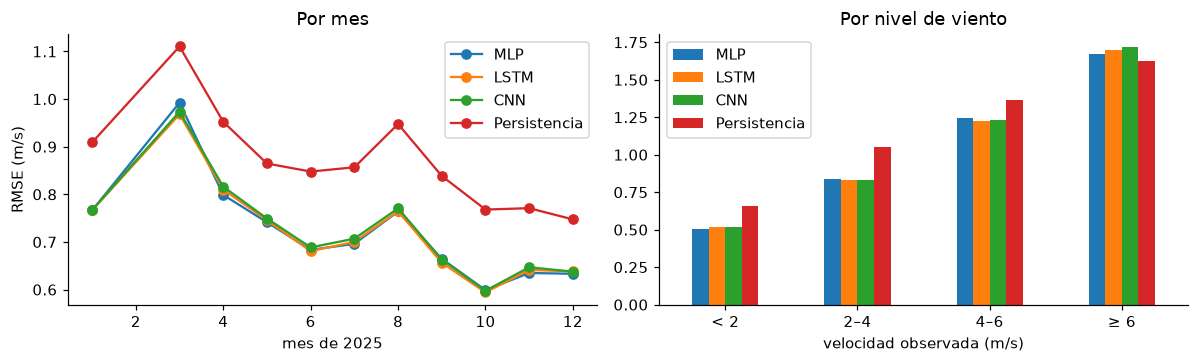

Sesgo por nivel (predicho − observado):
       MLP   LSTM    CNN  Persistencia
< 2  0.194  0.212  0.214         0.151
2–4 -0.319 -0.297 -0.288        -0.245
4–6 -0.746 -0.715 -0.744        -0.476
≥ 6 -1.225 -1.271 -1.274        -0.768


In [14]:
mes = pd.DatetimeIndex(hora).month
por_mes = err2.groupby(mes)[list(pm)].mean() ** 0.5
nivel = pd.cut(y, [0, 2, 4, 6, 30], right=False, labels=["< 2", "2–4", "4–6", "≥ 6"])
por_nivel = err2.groupby(nivel, observed=True)[list(pm)].mean() ** 0.5
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
por_mes.plot(ax=ax[0], marker="o"); ax[0].set(xlabel="mes de 2025", ylabel="RMSE (m/s)", title="Por mes")
por_nivel.plot.bar(ax=ax[1], rot=0); ax[1].set(xlabel="velocidad observada (m/s)", title="Por nivel de viento")
plt.tight_layout(); plt.show()
print("Sesgo por nivel (predicho − observado):")
print(pd.DataFrame({m: (pm[m] - y) for m in pm}).groupby(nivel, observed=True).mean().round(3).to_string())

## Predicciones frente a valores reales

Dos semanas de 2025 en la estación con más datos de prueba, con el pronóstico promedio de cada modelo y la
persistencia.

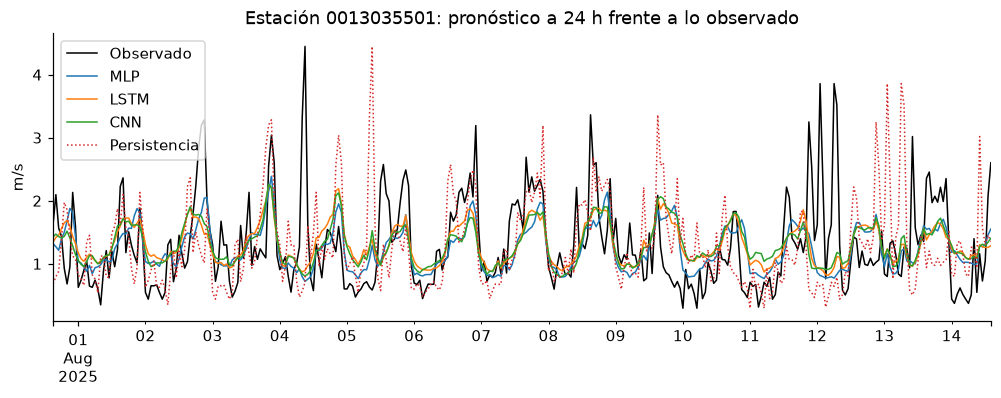

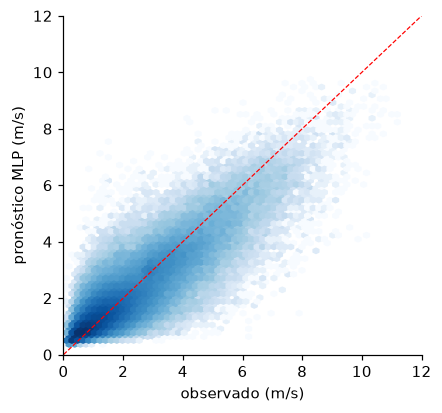

In [15]:
e_top = pd.Series(est).value_counts().index[0]
sel = np.flatnonzero(est == e_top)
serie = pd.DataFrame({"Observado": y[sel], **{m: pm[m][sel] for m in pm}}, index=pd.DatetimeIndex(hora[sel])).sort_index()
tramo = serie.loc[serie.index[len(serie) // 2]:].iloc[:336]
ax = tramo.plot(figsize=(11, 3.4), lw=1, style=["k-", "-", "-", "-", ":"])
ax.set(ylabel="m/s", title=f"Estación {e_top}: pronóstico a 24 h frente a lo observado")
plt.show()
plt.figure(figsize=(4.2, 4))
plt.hexbin(y, pm[mejor], gridsize=60, bins="log", cmap="Blues")
plt.plot([0, 12], [0, 12], "r--", lw=.8); plt.xlim(0, 12); plt.ylim(0, 12)
plt.xlabel("observado (m/s)"); plt.ylabel(f"pronóstico {mejor} (m/s)"); plt.show()

## Efecto de los valores atípicos

In [16]:
g_ = pd.DataFrame({"y": y, "est": est})
med = g_.groupby("est").y.transform("median"); mad = g_.groupby("est").y.transform(lambda x: (x - x.median()).abs().median())
atip = ((y - med) / (1.4826 * mad)).abs() > 6
print(f"Horas objetivo atípicas en prueba: {atip.sum()} ({atip.mean():.2%})")
print(pd.DataFrame({"RMSE con atípicos": {m: np.sqrt(np.mean((p - y) ** 2)) for m, p in pm.items()},
                    "RMSE sin atípicos": {m: np.sqrt(np.mean((p[~atip] - y[~atip]) ** 2)) for m, p in pm.items()}}).round(4))

Horas objetivo atípicas en prueba: 170 (0.08%)
              RMSE con atípicos  RMSE sin atípicos
MLP                      0.7010             0.6973
LSTM                     0.7022             0.6986
CNN                      0.7065             0.7029
Persistencia             0.8503             0.8475


## Baseline y umbral de mejora para modelos avanzados

In [17]:
mejor_media = tabla.loc[mejor_m, "RMSE media"]
otros = [m for m in MOD if m != mejor_m]
sd_dif = max((ps[ps.modelo == mejor_m].RMSE.to_numpy() - ps[ps.modelo == o].RMSE.to_numpy()).std(ddof=1) for o in otros)
mdd = (1.96 + 0.84) * sd_dif / np.sqrt(len(semillas))
print(f"Baseline: {mejor_m}, RMSE = {mejor_media:.4f} m/s "
      f"(IC 95 % {tabla.loc[mejor_m, 'RMSE IC95 inf']:.4f}–{tabla.loc[mejor_m, 'RMSE IC95 sup']:.4f})")
print(f"Diferencia mínima detectable con 6 semillas (potencia 0.80): {mdd:.4f} m/s | margen práctico δ = 0.02 m/s")
umbral = mejor_media - max(mdd, 0.02)
print(f"Un modelo avanzado debe lograr RMSE < {umbral:.4f} m/s en 2025 "
      f"(mejora ≥ {100 * max(mdd, 0.02) / mejor_media:.1f} %) para ser estadística y prácticamente mejor que el baseline.")

Baseline: MLP, RMSE = 0.7057 m/s (IC 95 % 0.7031–0.7082)
Diferencia mínima detectable con 6 semillas (potencia 0.80): 0.0070 m/s | margen práctico δ = 0.02 m/s
Un modelo avanzado debe lograr RMSE < 0.6857 m/s en 2025 (mejora ≥ 2.8 %) para ser estadística y prácticamente mejor que el baseline.
